# 实验 01：一维 Poisson 方程的最大误差认证

这是手写近似函数的基础实验，尚未训练 PINN。运行环境：Python 3、NumPy、Matplotlib。

问题为 $-u''=2$，区间为 $[0,1]$，边界为 $u(0)=u(1)=0$。精确解 $u^*(x)=x(1-x)$ 只用于检查实验结果，认证公式不需要访问精确解。

令 $v=u^*+e$，残差 $r=-v''-2=-e''$。若 $v$ 足够光滑、严格满足边界，且整个区间上 $|r|\leq\varepsilon$，则
$$|e(x)|\leq q(x)=\frac{\varepsilon}{2}x(1-x),\qquad \max|e|\leq\eta=\frac{\varepsilon}{8}.$$

证明：$(q-e)''=-\varepsilon+r\leq0$，$(q+e)''=-\varepsilon-r\leq0$；两者端点均为零，因此两者非负。

本实验使用可解析求得的全域残差上界。浮点运算给出的数值用于演示，并非经过向外舍入的机器级严格证书。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0.0, 1.0, 20001)
u_exact = x * (1.0 - x)

# 案例 A：平缓误差。解析最大误差为 0.1/4。
# 案例 B：振荡误差。二阶导数使振幅乘以 (4*pi)^2。
cases = [
    dict(name="A: smooth arch", error=0.1*x*(1-x),
         epsilon=0.2, true_max=0.025),
    dict(name="B: oscillatory", error=0.01*np.sin(4*np.pi*x),
         epsilon=0.01*(4*np.pi)**2, true_max=0.01),
]

print("case                 residual bound    error bound    true max error    ratio")
for case in cases:
    case["eta"] = case["epsilon"] / 8
    case["ratio"] = case["eta"] / case["true_max"]
    assert case["eta"] >= case["true_max"] - 1e-14
    assert np.max(np.abs(case["error"])) <= case["eta"] + 1e-14
    assert np.allclose(case["error"][[0, -1]], 0.0, atol=1e-14)
    print(f'{case["name"]:20s} {case["epsilon"]:14.6f} '
          f'{case["eta"]:14.6f} {case["true_max"]:17.6f} {case["ratio"]:8.3f}')


case                 residual bound    error bound    true max error    ratio
A: smooth arch             0.200000       0.025000          0.025000    1.000
B: oscillatory             1.579137       0.197392          0.010000   19.739


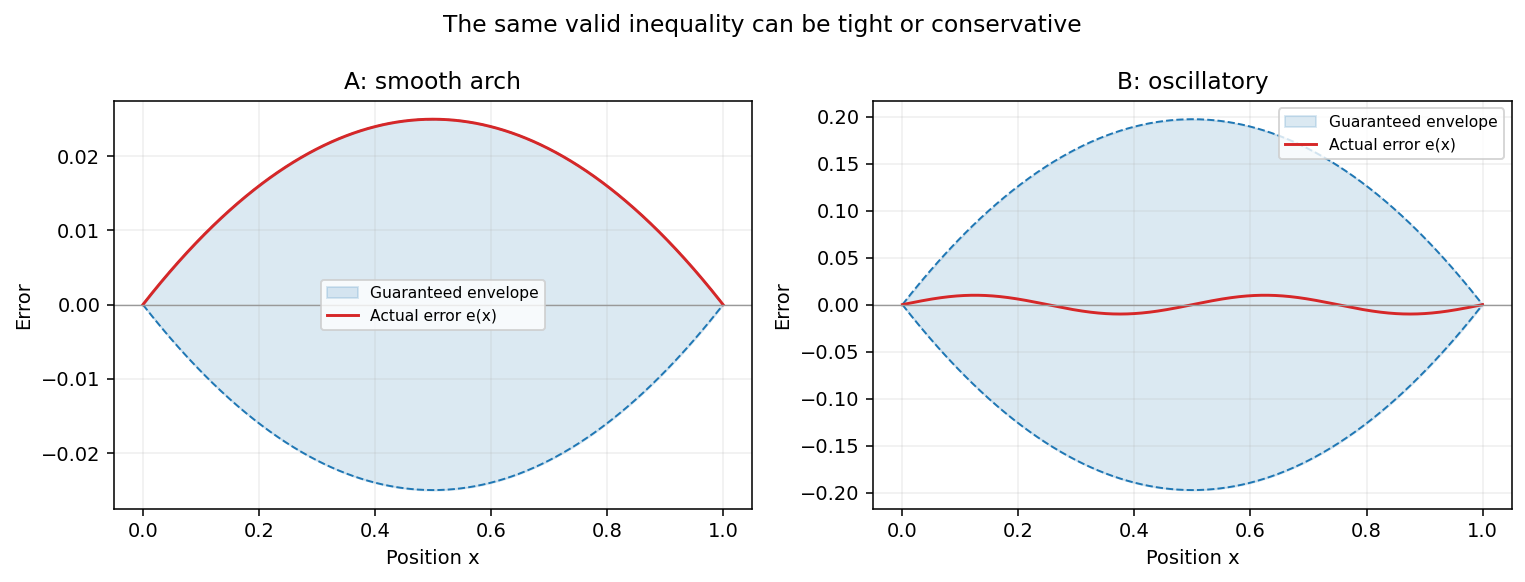

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, case in zip(axes, cases):
    q = case["epsilon"] / 2 * x * (1-x)
    ax.fill_between(x, -q, q, alpha=0.16, color="tab:blue", label="Guaranteed envelope")
    ax.plot(x, q, "--", color="tab:blue", linewidth=1)
    ax.plot(x, -q, "--", color="tab:blue", linewidth=1)
    ax.plot(x, case["error"], color="tab:red", label="Actual error e(x)")
    ax.axhline(0, color="0.6", linewidth=0.7)
    ax.set(title=case["name"], xlabel="Position x", ylabel="Error")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle("The same valid inequality can be tight or conservative")
fig.tight_layout()
plt.show()


## 观察：可靠性与紧致程度

A 的上界等于真实最大误差。B 的上界约为真实误差的 19.74 倍，仍然有效，却较宽松。

原因之一是振荡函数的二阶导数可能较大，而函数幅值仍较小；统一使用残差最大值的公式没有利用振荡的详细结构。

这里的比值是“认证上界 / 真实最大误差”。它用于有已知参考解的实验评估；实际认证时通常不知道分母。

## 采样陷阱：检查点之间也可能存在大残差

再取 $e(x)=0.01\sin(20\pi x)$。在 $x_i=i/10$ 上，残差在精确数学中恰好为零，但点之间并不为零。该例是刻意构造的反例，不代表所有随机采样都会失败。


Residual maximum observed at 11 points: 2.225e-13
Analytic global residual maximum:       39.478418
Incorrect plug-in bound from sampling:  2.781e-14
Valid bound from analytic residual:     4.934802
True maximum solution error:            0.010000


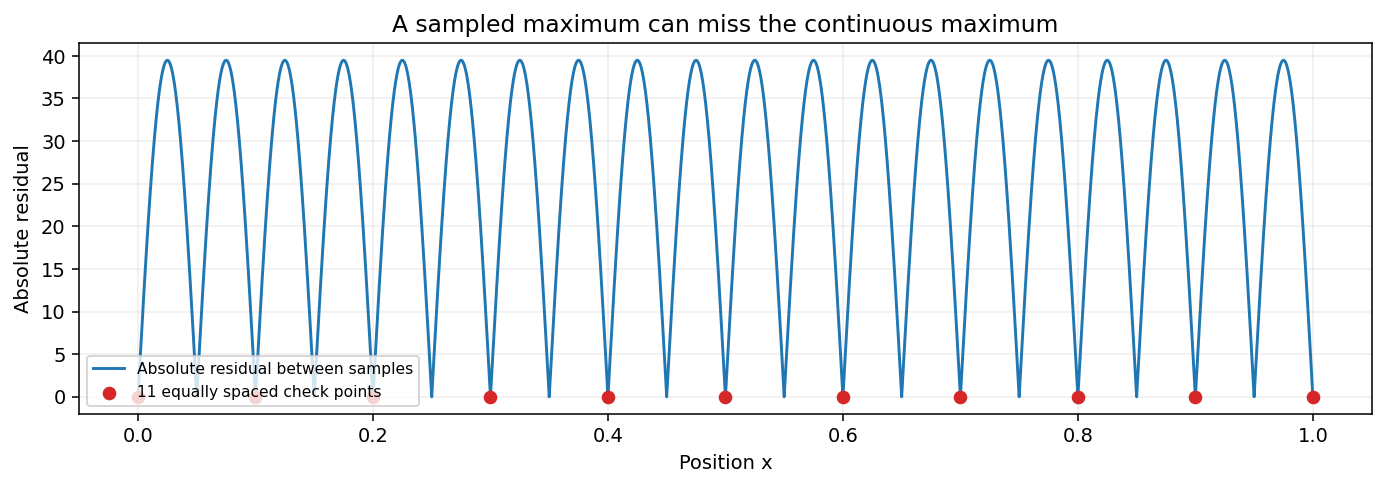

In [3]:
k = 20
amplitude = 0.01
sample_x = np.linspace(0.0, 1.0, 11)
def residual(z):
    return amplitude * (k*np.pi)**2 * np.sin(k*np.pi*z)

sample_max = np.max(np.abs(residual(sample_x)))
analytic_epsilon = amplitude * (k*np.pi)**2
print(f"Residual maximum observed at 11 points: {sample_max:.3e}")
print(f"Analytic global residual maximum:       {analytic_epsilon:.6f}")
print(f"Incorrect plug-in bound from sampling:  {sample_max/8:.3e}")
print(f"Valid bound from analytic residual:     {analytic_epsilon/8:.6f}")
print(f"True maximum solution error:            {amplitude:.6f}")
assert sample_max/8 < amplitude
assert analytic_epsilon/8 >= amplitude

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(x, np.abs(residual(x)), label="Absolute residual between samples")
ax.scatter(sample_x, np.abs(residual(sample_x)), color="tab:red", zorder=3,
           label="11 equally spaced check points")
ax.set(xlabel="Position x", ylabel="Absolute residual",
       title="A sampled maximum can miss the continuous maximum")
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## 下一步：接入 PINN

1. 用 $v_\theta(x)=x(1-x)N_\theta(x)$ 严格满足零边界。
2. 用自动微分计算 $r_\theta=-v_\theta''-f$，训练网络。
3. 独立报告配点残差、加密网格残差、参考解误差，以及残差估计对应的误差估计。
4. 要把误差估计升级为严格认证，需给出全域残差的保证，例如使用区间界，或经过证明的导数界与覆盖网格修正。加密采样本身不是证明。

本笔记复现经典一维误差界并检查实现，不将它宣称为新的理论贡献，也不将这些手写函数的结果当作 PINN 实验结果。
